# **Pengembangan Model MLP: Arsitektur, Regularisasi, dan Training**

Notebook ini membangun arsitektur MLP untuk prediksi risiko diabetes dan menentukan konfigurasinya lewat eksperimen bertahap. Ada tiga hal yang dikerjakan:

1. Merancang arsitektur MLP beserta alasan teknis untuk jumlah layer, neuron, aktivasi, dropout, dan regularisasi L2.
2. Melatih model dengan optimizer Adam, EarlyStopping, dan ModelCheckpoint berdasarkan metrik validation.
3. Membaca kurva loss dan metrik train vs validation untuk melihat tanda overfitting atau underfitting.

Keputusan yang sudah dikunci kelompok sebelum eksperimen:

| Aspek | Keputusan |
|---|---|
| Aktivasi hidden layer | ReLU |
| Optimizer | Adam |
| Input pipeline | `tf.data` lewat helper `make_dataset()` |
| Pengulangan | Setiap konfigurasi dijalankan dengan 3 seed (42, 123, 2026) |
| Loss selama eksperimen | Binary cross-entropy (Focal Loss baru dipasang di notebook fitur unik 1) |
| Data yang dipakai | Train untuk melatih, validation untuk memilih. **Data test tidak disentuh** |

Learning rate dan batch size dituning di `04_eksperimen_optimasi.ipynb`. Di notebook ini keduanya ditahan di nilai awal.

**Penanggung jawab:** Wilbert Edric Tanjiro (231110595)

## **1. Import Library dan Konfigurasi**

Seluruh fungsi model, pipeline data, dan eksperimen ada di `src/model.py`, jadi notebook lain memakai kode yang sama persis.

Eksperimen di notebook ini melatih 30 model dan butuh waktu cukup lama (sekitar 30 sampai 60 menit di CPU, tergantung laptop). Karena itu ada saklar `RUN_EXPERIMENTS`:
- `True`: semua eksperimen dijalankan ulang, lalu hasilnya disimpan ke `reports/results/`.
- `False`: hasil eksperimen yang sudah tersimpan dimuat dari `reports/results/`, sehingga notebook selesai dalam hitungan detik.

In [11]:
import sys
import json
import time
import platform
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.append(str(ROOT))

import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import tensorflow as tf
import keras

from src import config
from src import preprocessing as prep
from src import model as M

RUN_EXPERIMENTS = False

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 10})
WARNA_TRAIN, WARNA_VAL, WARNA_ABU, WARNA_PILIH = "#DD8452", "#4C72B0", "#9A9A9A", "#4C72B0"
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
config.RESULTS_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(fig, name):
    fig.savefig(config.FIGURES_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

print("TensorFlow :", tf.__version__)
print("Keras      :", keras.__version__)
print("Python     :", platform.python_version())
print("Seed       :", M.SEEDS)
print("Konfigurasi awal:", M.DEFAULT_CONFIG)
print("RUN_EXPERIMENTS :", RUN_EXPERIMENTS)

TensorFlow : 2.21.0
Keras      : 3.15.1
Python     : 3.12.10
Seed       : [42, 123, 2026]
Konfigurasi awal: {'hidden_units': [128, 64], 'dropout': 0.2, 'l2': 0.0, 'batch_norm': False, 'learning_rate': 0.001, 'batch_size': 512}
RUN_EXPERIMENTS : False


## **2. Memuat Data Hasil Preprocessing**

Data diambil lewat `prepare_datasets()` dari `src/preprocessing.py`. Fingerprint data test dicocokkan dengan yang tersimpan di `models/preprocessing_config.json` untuk memastikan pembagian data sama dengan notebook 02. Data test ikut dimuat karena berasal dari fungsi yang sama, tetapi tidak dipakai sama sekali di notebook ini.

In [12]:
data = prep.prepare_datasets()
cfg_prep = prep.load_preprocessing_config()
assert data["test_fingerprint"] == cfg_prep["split"]["test_fingerprint"], "Split data berbeda dengan notebook 02"

for part in ["train", "val"]:
    X, y = data[f"X_{part}"], data[f"y_{part}"]
    print(f"{part:<5}: X {X.shape}, {X.dtype} | kelas 1 = {y.mean():.2%}")
print("Fingerprint test cocok:", data["test_fingerprint"])

train: X (160211, 21), float32 | kelas 1 = 15.30%
val  : X (34332, 21), float32 | kelas 1 = 15.30%
Fingerprint test cocok: 01b58633cb6f22b5


## **3. Pipeline Input dengan `tf.data`**

Data train dan validation diubah menjadi `tf.data.Dataset` lewat `M.make_dataset()` dengan urutan **shuffle, batch, prefetch**:
- **Shuffle** memakai buffer seukuran seluruh data train dengan seed tetap, dan diacak ulang di setiap epoch. Data validation tidak diacak.
- **Batch** membagi data menjadi kelompok kecil sesuai batch size.
- **Prefetch** menyiapkan batch berikutnya selagi model memproses batch saat ini.

Pengecekan di bawah memastikan pengacakannya bisa diulang. Dua dataset dengan seed sama harus menghasilkan batch pertama yang identik, sedangkan seed berbeda menghasilkan urutan yang berbeda.

In [13]:
bs = M.DEFAULT_CONFIG["batch_size"]
ds_a = M.make_dataset(data["X_train"], data["y_train"], bs, shuffle=True, seed=42)
ds_b = M.make_dataset(data["X_train"], data["y_train"], bs, shuffle=True, seed=42)
ds_c = M.make_dataset(data["X_train"], data["y_train"], bs, shuffle=True, seed=123)

xa, ya = next(iter(ds_a))
xb, _ = next(iter(ds_b))
xc, _ = next(iter(ds_c))

print("Element spec      :", ds_a.element_spec)
print("Jumlah batch train:", int(ds_a.cardinality()))
print("Bentuk satu batch :", tuple(xa.shape), tuple(ya.shape))
print("Seed sama  -> batch pertama identik :", bool(np.array_equal(xa.numpy(), xb.numpy())))
print("Seed beda  -> batch pertama identik :", bool(np.array_equal(xa.numpy(), xc.numpy())))
print(f"Proporsi kelas 1 di batch pertama  : {ya.numpy().mean():.2%}")

Element spec      : (TensorSpec(shape=(None, 21), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.float32, name=None))
Jumlah batch train: 313
Bentuk satu batch : (512, 21) (512,)
Seed sama  -> batch pertama identik : True
Seed beda  -> batch pertama identik : False
Proporsi kelas 1 di batch pertama  : 13.28%


**Interpretasi:** Pipeline `tf.data` menghasilkan batch berukuran (512, 21) dengan tipe `float32`, dan satu epoch terdiri dari 313 batch. Angka 313 berasal dari 160.211 baris dibagi 512, dengan batch terakhir berisi sisa data yang lebih sedikit. Dua dataset dengan seed yang sama menghasilkan batch pertama yang identik, sedangkan seed berbeda menghasilkan urutan lain. Artinya pengacakan data sudah terkunci, dan ini salah satu syarat supaya hasil training bisa diulang.

Proporsi kelas 1 di batch pertama adalah 17,97%, sedikit di atas proporsi keseluruhan (15,30%). Variasi seperti ini wajar karena batch diambil acak. Dengan batch size 512, setiap batch tetap berisi puluhan sampel diabetes, jadi gradien dari kelas positif tidak hilang di satu batch tertentu.

## **4. Rancangan Arsitektur dan Alasan Teknis**

Arsitektur dirancang sebagai MLP berbentuk corong, yaitu jumlah neuron mengecil di setiap layer berikutnya. Setiap hidden layer tersusun dari **Dense, ReLU, lalu Dropout**. Kalau Batch Normalization dipakai, posisinya di antara Dense dan ReLU.

| Komponen | Pilihan awal | Alasan teknis |
|---|---|---|
| Input | 21 neuron | Sesuai jumlah fitur setelah preprocessing |
| Jumlah hidden layer | 2 (diuji 2 dan 3) | Fitur sudah berupa indikator bermakna, jadi tidak butuh jaringan yang sangat dalam. Satu layer saja kurang leluasa memodelkan interaksi antarfitur, sedangkan 4 layer ke atas berisiko overfit tanpa manfaat jelas pada 21 fitur |
| Neuron | 128 lalu 64 (diuji 64 sampai 256 di layer pertama) | Layer pertama sekitar 3 sampai 12 kali jumlah input supaya cukup ruang untuk kombinasi fitur, lalu dibagi dua di layer berikutnya untuk merangkum informasi menuju output |
| Aktivasi | ReLU dengan inisialisasi He normal | ReLU murah dihitung dan tidak mengalami *vanishing gradient* seperti sigmoid atau tanh di hidden layer. Inisialisasi He dirancang khusus untuk ReLU (He dkk., 2015) |
| Dropout | 0,2 (diuji 0 sampai 0,3) | Mematikan sebagian neuron secara acak saat training supaya model tidak bergantung pada pola tertentu (Srivastava dkk., 2014) |
| Regularisasi L2 | Tidak ada (diuji 1e-5 dan 1e-4) | Menghukum bobot yang terlalu besar. Diuji terpisah karena EarlyStopping dan dropout mungkin sudah cukup |
| Batch Normalization | Tidak ada (diuji) | Menstabilkan distribusi aktivasi (Ioffe & Szegedy, 2015). Input sudah di-scaling, jadi manfaatnya belum tentu terasa pada jaringan dangkal |
| Output | 1 neuron sigmoid | Menghasilkan probabilitas diabetes antara 0 dan 1 |
| Loss | Binary cross-entropy | Loss standar untuk klasifikasi biner dengan output probabilitas |
| Optimizer | Adam, learning rate 0,001 | Adam menyesuaikan learning rate per parameter dan stabil tanpa banyak tuning. Nilai 0,001 adalah nilai yang direkomendasikan di paper aslinya (Kingma & Ba, 2015) dan dituning lebih lanjut di notebook 04 |
| Batch size | 512 (sementara) | Cukup besar supaya setiap batch rata-rata berisi sekitar 78 sampel kelas 1, sehingga gradien tidak terlalu berisik. Dituning di notebook 04 |
| EarlyStopping | Pantau PR-AUC validation, patience 8, kembalikan bobot terbaik | Menghentikan training saat performa validation berhenti membaik (Prechelt, 1998) |
| ModelCheckpoint | Simpan bobot dengan PR-AUC validation terbaik | Bobot terbaik tersimpan ke file walaupun training masih berlanjut beberapa epoch setelahnya |
| Epoch maksimum | 100 | Batas atas saja, karena training hampir selalu berhenti lebih dulu oleh EarlyStopping |

**Alasan memakai PR-AUC, bukan accuracy.** Model yang selalu menebak "tidak diabetes" sudah mendapat accuracy sekitar 85%. PR-AUC (*average precision*) hanya berfokus pada seberapa baik model menemukan kelas positif, sehingga lebih informatif untuk data tidak seimbang (Saito & Rehmsmeier, 2015). Nilai acuannya adalah proporsi kelas positif, yaitu sekitar 0,153. Model yang tidak belajar apa pun akan mendapat PR-AUC di sekitar angka itu. ROC-AUC tetap dicatat sebagai metrik pendamping.

In [14]:
model_awal = M.build_model(**M.DEFAULT_CONFIG)
model_awal.summary()
print(f"Jumlah parameter yang dilatih: {model_awal.count_params():,}")

Model: "mlp_diabetes"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ fitur_input (InputLayer)        │ (None, 21)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │         2,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_1 (Activation)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_2 (Activation)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,137 (43.50 KB)

 Trainable params: 11,137 (43.50 KB)

 Non-trainable params: 0 (0.00 B)

Jumlah parameter yang dilatih: 11,137


**Interpretasi:** Model awal punya 11.137 parameter yang dilatih. Rinciannya: `dense_1` sebanyak 2.816 (21 x 128 bobot ditambah 128 bias), `dense_2` sebanyak 8.256 (128 x 64 ditambah 64), dan layer output sebanyak 65. Layer ReLU dan Dropout tidak punya parameter karena hanya mengubah nilai aktivasi.

Dibanding jumlah data train yang mencapai 160.211 baris, model ini tergolong kecil, yaitu sekitar 14 sampel untuk setiap parameter. Dengan perbandingan seperti ini, risiko model menghafal data train relatif kecil. Itu juga alasan kandidat terbesar di eksperimen E1 dibatasi sekitar 47 ribu parameter.

## **5. Protokol Eksperimen**

Eksperimen dilakukan bertahap. Setiap tahap mengubah satu kelompok faktor dan mengunci pemenang tahap sebelumnya:

| Tahap | Yang diuji | Kandidat |
|---|---|---|
| E1 | Kedalaman dan lebar | [64-32], [128-64], [256-128], [128-64-32], [256-128-64] |
| E2a | Dropout | 0, 0,2, 0,3 |
| E2b | Regularisasi tambahan | tanpa tambahan, L2 1e-5, L2 1e-4, Batch Normalization |

**Aturan pemilihan** (fungsi `M.select_best()`):
1. Cari skenario dengan rata-rata PR-AUC validation tertinggi dari 3 seed.
2. Skenario lain dianggap **setara** kalau rata-ratanya tidak lebih rendah dari (terbaik dikurangi 1 standar deviasi skenario terbaik).
3. Dari skenario yang setara, pilih yang **paling sederhana**, yaitu komponen tambahan (L2, Batch Normalization) paling sedikit, lalu jumlah parameter paling sedikit.

Aturan ini dipakai supaya selisih yang hanya terjadi karena kebetulan seed tidak dianggap sebagai keunggulan. Dengan 3 seed, standar deviasi masih berupa perkiraan kasar, jadi aturan ini sifatnya heuristik yang konservatif.

Konfigurasi yang persis sama dengan run sebelumnya tidak dilatih ulang, tetapi hasilnya dipakai lagi. Karena training sudah deterministik, hasilnya akan sama persis.

In [15]:
RUNS_PATH = config.RESULTS_DIR / "03_eksperimen_runs.csv"
HIST_PATH = config.RESULTS_DIR / "03_riwayat_training.json"

if RUN_EXPERIMENTS:
    cache, kumpulan_runs, kumpulan_hist = {}, [], {}
    waktu_mulai = time.time()
else:
    runs_tersimpan = pd.read_csv(RUNS_PATH)
    hist_tersimpan = M.load_json(HIST_PATH)
    print(f"Memuat {len(runs_tersimpan)} run dari {RUNS_PATH.relative_to(ROOT)}")

def jalankan_tahap(tahap, configs):
    """Menjalankan (atau memuat) semua skenario dalam satu tahap eksperimen."""
    if RUN_EXPERIMENTS:
        runs, hist = M.run_configs(configs, data, prefix=tahap, cache=cache)
        runs.insert(0, "tahap", tahap)
        kumpulan_runs.append(runs)
        kumpulan_hist.update({f"{tahap}|{k}": v for k, v in hist.items()})
    else:
        runs = runs_tersimpan[runs_tersimpan["tahap"] == tahap].reset_index(drop=True)
        assert list(dict.fromkeys(runs["skenario"])) == list(configs), "Skenario tersimpan tidak cocok"
        hist = {k.split("|", 1)[1]: v for k, v in hist_tersimpan.items() if k.startswith(f"{tahap}|")}
    return runs, hist

def tabel_ringkas(summary, terpilih):
    t = summary[["config", "params", "val_pr_auc_mean", "val_pr_auc_std", "val_roc_auc_mean",
                 "train_pr_auc_mean", "gap_pr_auc_mean", "best_epoch_mean", "seconds_mean",
                 "setara_dengan_terbaik"]].copy()
    t.columns = ["konfigurasi", "parameter", "val PR-AUC", "std", "val ROC-AUC", "train PR-AUC",
                 "gap train-val", "epoch terbaik", "detik/run", "setara terbaik"]
    t["dipilih"] = ["ya" if i == terpilih else "" for i in t.index]
    return t.round({"val PR-AUC": 4, "std": 4, "val ROC-AUC": 4, "train PR-AUC": 4,
                    "gap train-val": 4, "epoch terbaik": 1, "detik/run": 0})

def plot_tahap(runs, summary, terpilih, judul, nama_file):
    """Dot plot: titik kecil = tiap seed, titik besar + garis = rata-rata dan +-1 std."""
    urutan = list(summary.index)
    fig, ax = plt.subplots(figsize=(max(6, 1.6 * len(urutan)), 4))
    for i, sk in enumerate(urutan):
        warna = WARNA_PILIH if sk == terpilih else WARNA_ABU
        nilai = runs.loc[runs["skenario"] == sk, "val_pr_auc"]
        ax.scatter(np.full(len(nilai), i) + np.array([-0.08, 0, 0.08])[:len(nilai)], nilai,
                   s=18, color=warna, alpha=0.5, zorder=2)
        m, s = summary.loc[sk, "val_pr_auc_mean"], summary.loc[sk, "val_pr_auc_std"]
        ax.errorbar(i + 0.25, m, yerr=s, fmt="o", ms=8, color=warna, capsize=4, lw=2, zorder=3)
        ax.annotate(f"{m:.4f}", (i + 0.33, m), va="center", fontsize=9, color="#333333")
    batas = summary.loc[summary["val_pr_auc_mean"].idxmax(), "val_pr_auc_mean"] - \
            summary.loc[summary["val_pr_auc_mean"].idxmax(), "val_pr_auc_std"]
    ax.axhline(batas, ls=":", color="#555555", lw=1)
    ax.text(-0.45, batas, "batas setara", va="bottom", ha="left", fontsize=8, color="#555555")
    ax.set_xticks(range(len(urutan)), [f"{sk}\n({summary.loc[sk, 'params']:,} param)" for sk in urutan])
    ax.set_xlim(-0.5, len(urutan) - 0.2)
    ax.set_ylabel("PR-AUC validation")
    ax.set_title(judul, fontweight="bold")
    ax.legend(handles=[mpatches.Patch(color=WARNA_PILIH, label="dipilih"),
                       mpatches.Patch(color=WARNA_ABU, label="kandidat lain")],
              loc="lower right", fontsize=8)
    fig.text(0.01, -0.02, "Titik kecil = hasil tiap seed. Titik besar dan garis = rata-rata +- 1 std. "
             "Sumbu y diperbesar dan tidak dimulai dari 0.", fontsize=8, color="#555555")
    fig.tight_layout()
    save_fig(fig, nama_file)
    plt.show()

Memuat 36 run dari reports\results\03_eksperimen_runs.csv


## **6. Eksperimen E1: Kedalaman dan Lebar Jaringan**

Lima arsitektur dibandingkan dengan dropout 0,2, tanpa L2, tanpa Batch Normalization, learning rate 0,001, dan batch size 512. Kandidatnya mencakup dua kedalaman (2 dan 3 hidden layer) dan tiga lebar layer pertama (64, 128, 256). Proses ini paling lama di notebook karena melatih 15 model.

In [16]:
def dengan(cfg, **ubah):
    baru = dict(cfg)
    baru.update(ubah)
    return baru

configs_e1 = {
    "64-32": dengan(M.DEFAULT_CONFIG, hidden_units=[64, 32]),
    "128-64": dengan(M.DEFAULT_CONFIG, hidden_units=[128, 64]),
    "256-128": dengan(M.DEFAULT_CONFIG, hidden_units=[256, 128]),
    "128-64-32": dengan(M.DEFAULT_CONFIG, hidden_units=[128, 64, 32]),
    "256-128-64": dengan(M.DEFAULT_CONFIG, hidden_units=[256, 128, 64]),
}
runs_e1, hist_e1 = jalankan_tahap("E1", configs_e1)

In [17]:
def dengan(cfg, **ubah):
    baru = dict(cfg)
    baru.update(ubah)
    return baru

configs_e1 = {
    "64-32": dengan(M.DEFAULT_CONFIG, hidden_units=[64, 32]),
    "128-64": dengan(M.DEFAULT_CONFIG, hidden_units=[128, 64]),
    "256-128": dengan(M.DEFAULT_CONFIG, hidden_units=[256, 128]),
    "128-64-32": dengan(M.DEFAULT_CONFIG, hidden_units=[128, 64, 32]),
    "256-128-64": dengan(M.DEFAULT_CONFIG, hidden_units=[256, 128, 64]),
}
runs_e1, hist_e1 = jalankan_tahap("E1", configs_e1)

,konfigurasi,parameter,val PR-AUC,std,val ROC-AUC,train PR-AUC,gap train-val,epoch terbaik,detik/run,setara terbaik,dipilih
skenario,,,,,,,,,,,
64-32,[64-32] do=0.2,3521,0.4436,0.0011,0.8186,0.4431,-0.0005,23.0,67.0,False,
128-64,[128-64] do=0.2,11137,0.4468,0.0015,0.8187,0.4498,0.0030,18.3,66.0,True,ya
256-128,[256-128] do=0.2,38657,0.4469,0.0008,0.8190,0.4515,0.0046,12.7,71.0,True,
128-64-32,[128-64-32] do=0.2,13185,0.4459,0.0006,0.8184,0.4445,-0.0014,17.3,66.0,False,
256-128-64,[256-128-64] do=0.2,46849,0.4462,0.0021,0.8185,0.4476,0.0013,12.7,73.0,True,


Arsitektur terpilih: 128-64


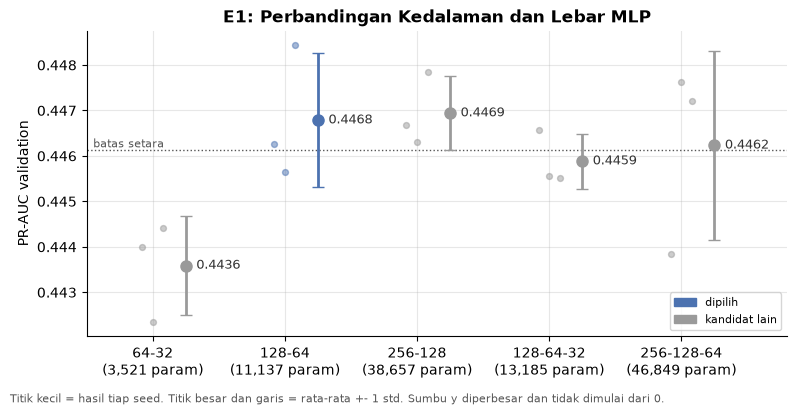

In [18]:
pilih_e1, ringkas_e1 = M.select_best(M.summarize(runs_e1))
cfg_e1 = configs_e1[pilih_e1]
display(tabel_ringkas(ringkas_e1, pilih_e1))
print("Arsitektur terpilih:", pilih_e1)
plot_tahap(runs_e1, ringkas_e1, pilih_e1, "E1: Perbandingan Kedalaman dan Lebar MLP", "model_01_e1_arsitektur")

**Interpretasi:** Hasil paling penting dari E1 justru betapa miripnya kelima arsitektur. Rata-rata PR-AUC validation semuanya berada di rentang 0,4436 sampai 0,4469, selisihnya hanya 0,0033.

- **[64-32]** dengan 3.521 parameter mendapat nilai terendah (0,4436) dan berada di bawah batas setara. Model sekecil ini sepertinya sedikit kekurangan kapasitas.
- **[256-128]** mendapat rata-rata tertinggi (0,4469), tetapi hanya unggul 0,0001 dari [128-64] padahal parameternya 3,5 kali lebih banyak (38.657 berbanding 11.137).
- **[256-128-64]** yang paling besar (46.849 parameter) tidak lebih baik (0,4462) dan hasilnya paling tidak stabil antar-seed (std 0,0021).
- **[128-64-32]** mendapat 0,4459, tipis di bawah batas setara (0,4461). Menambah layer ketiga ke [128-64] tidak memberi keuntungan.

Sesuai aturan pemilihan, **[128-64]** dipilih karena paling sederhana di antara kandidat yang setara. Model yang lebih besar juga mencapai epoch terbaiknya lebih cepat (rata-rata 12,7 epoch, dibanding 18,3 untuk [128-64]) dan gap train-val-nya sedikit lebih besar (0,0046 untuk [256-128]). Ini tanda model besar mulai menyesuaikan diri terlalu cepat dengan data train.

Kesimpulannya, menambah lebar atau kedalaman jaringan hampir tidak berpengaruh. Ini sejalan dengan temuan EDA bahwa sinyal di 21 fitur memang terbatas. Yang membatasi performa kemungkinan besar adalah informasi di data, bukan ukuran model.

## **7. Eksperimen E2a: Besar Dropout**

Arsitektur pemenang E1 diuji dengan tiga nilai dropout. Skenario dropout 0,2 identik dengan pemenang E1, jadi hasilnya dipakai ulang tanpa training baru. Untuk dropout, ketiga skenario punya jumlah parameter yang sama, sehingga yang menentukan adalah rata-rata PR-AUC di antara skenario yang setara.

,konfigurasi,parameter,val PR-AUC,std,val ROC-AUC,train PR-AUC,gap train-val,epoch terbaik,detik/run,setara terbaik,dipilih
skenario,,,,,,,,,,,
dropout 0.0,[128-64] do=0.0,11137,0.4449,0.0008,0.8174,0.4458,0.0009,6.7,26.0,False,
dropout 0.2,[128-64] do=0.2,11137,0.4468,0.0015,0.8187,0.4498,0.0030,18.3,66.0,True,ya
dropout 0.3,[128-64] do=0.3,11137,0.4462,0.0013,0.8185,0.4438,-0.0024,16.0,59.0,True,


Dropout terpilih: dropout 0.2


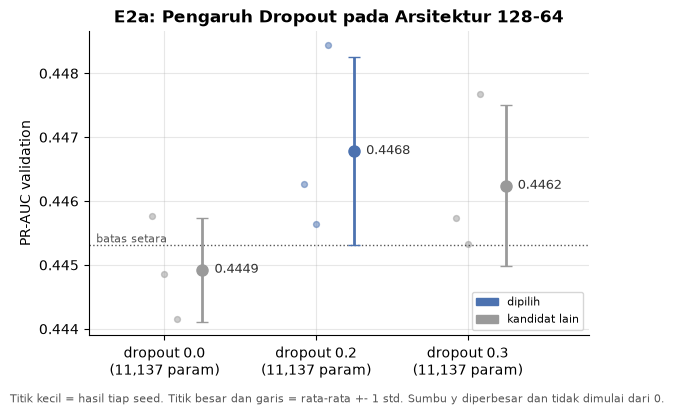

In [19]:
configs_e2a = {f"dropout {p}": dengan(cfg_e1, dropout=p) for p in [0.0, 0.2, 0.3]}
runs_e2a, hist_e2a = jalankan_tahap("E2a", configs_e2a)
pilih_e2a, ringkas_e2a = M.select_best(M.summarize(runs_e2a))
cfg_e2a = configs_e2a[pilih_e2a]
display(tabel_ringkas(ringkas_e2a, pilih_e2a))
print("Dropout terpilih:", pilih_e2a)
plot_tahap(runs_e2a, ringkas_e2a, pilih_e2a, f"E2a: Pengaruh Dropout pada Arsitektur {pilih_e1}", "model_02_e2a_dropout")

**Interpretasi:** Tanpa dropout, PR-AUC validation turun menjadi 0,4449 dan berada di luar batas setara. Yang lebih menarik adalah epoch terbaiknya, rata-rata hanya 6,7. Tanpa dropout, model mencapai puncak sangat cepat lalu performa validation mulai memburuk, sehingga EarlyStopping menghentikan training sekitar 11 sampai 17 epoch. Ini pola awal overfitting.

Dropout 0,2 (0,4468) dan 0,3 (0,4462) sama-sama setara. Dropout 0,2 dipilih karena rata-ratanya lebih tinggi dengan jumlah parameter yang sama. Pada dropout 0,3, PR-AUC train justru lebih rendah daripada validation (gap -0,0024). Artinya regularisasi mulai terlalu menahan model, sehingga tidak ada alasan menaikkan dropout lebih tinggi lagi.

## **8. Eksperimen E2b: L2 dan Batch Normalization**

Konfigurasi terbaik dari E2a dibandingkan dengan tiga variasi tambahan, yaitu L2 1e-5, L2 1e-4, dan Batch Normalization. Skenario tanpa tambahan dipakai ulang dari E2a. Sesuai aturan pemilihan, L2 atau Batch Normalization hanya dipakai kalau hasilnya **lebih baik secara jelas**, bukan sekadar sedikit lebih tinggi.

Catatan: jumlah parameter Batch Normalization sudah termasuk statistik rata-rata dan variansi yang tidak dilatih, sedangkan bias Dense dihapus karena perannya digantikan Batch Normalization.

,konfigurasi,parameter,val PR-AUC,std,val ROC-AUC,train PR-AUC,gap train-val,epoch terbaik,detik/run,setara terbaik,dipilih
skenario,,,,,,,,,,,
tanpa tambahan,[128-64] do=0.2,11137,0.4468,0.0015,0.8187,0.4498,0.0030,18.3,66.0,True,ya
L2 1e-5,[128-64] do=0.2 l2=1e-05,11137,0.4473,0.0005,0.8189,0.4475,0.0002,18.3,59.0,True,
L2 1e-4,[128-64] do=0.2 l2=0.0001,11137,0.4468,0.0010,0.8188,0.4400,-0.0068,16.0,52.0,True,
BatchNorm,[128-64] do=0.2 BN,11713,0.4478,0.0011,0.8197,0.4490,0.0012,30.7,101.0,True,


Regularisasi terpilih: tanpa tambahan


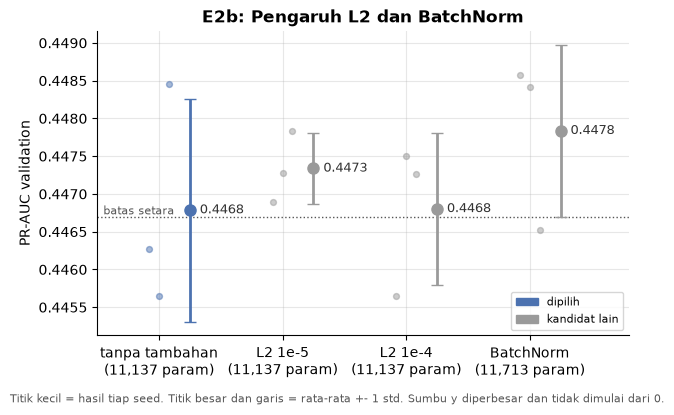

In [20]:
configs_e2b = {
    "tanpa tambahan": cfg_e2a,
    "L2 1e-5": dengan(cfg_e2a, l2=1e-5),
    "L2 1e-4": dengan(cfg_e2a, l2=1e-4),
    "BatchNorm": dengan(cfg_e2a, batch_norm=True),
}
runs_e2b, hist_e2b = jalankan_tahap("E2b", configs_e2b)
pilih_e2b, ringkas_e2b = M.select_best(M.summarize(runs_e2b))
cfg_final = configs_e2b[pilih_e2b]
display(tabel_ringkas(ringkas_e2b, pilih_e2b))
print("Regularisasi terpilih:", pilih_e2b)
plot_tahap(runs_e2b, ringkas_e2b, pilih_e2b, "E2b: Pengaruh L2 dan BatchNorm", "model_03_e2b_regularisasi")

**Interpretasi:** Keempat skenario masuk kategori setara, jadi tidak ada regularisasi tambahan yang terbukti lebih baik secara jelas.

- **Batch Normalization** mendapat rata-rata tertinggi (0,4478), unggul 0,0010 dari skenario tanpa tambahan. Tetapi selisih ini lebih kecil dari standar deviasi skenario tanpa tambahan sendiri (0,0015), dan satu seed Batch Normalization (2026) hanya mendapat 0,4465. Batch Normalization juga butuh epoch lebih banyak (rata-rata 30,7) dan waktu training sekitar 1,5 kali lebih lama (101 detik berbanding 66 detik per run).
- **L2 1e-5** sedikit lebih tinggi (0,4473) dengan hasil paling stabil (std 0,0005), tetapi perbedaannya juga masih dalam rentang variasi seed.
- **L2 1e-4** mendapat 0,4468 dengan PR-AUC train hanya 0,4400, lebih rendah dari validation (gap -0,0068). Ini tanda regularisasi terlalu kuat sehingga model mulai *underfit*.

Sesuai aturan pemilihan, konfigurasi **tanpa tambahan** dipilih karena paling sederhana. Perlu dicatat bahwa keputusan ini tipis, karena rata-rata skenario tanpa tambahan (0,4468) hanya sedikit di atas batas setara (0,4467). Dengan 3 seed, keunggulan kecil Batch Normalization belum bisa dibedakan dari kebetulan, jadi kami memilih model yang lebih sederhana dan lebih cepat dilatih.

## **9. Menyimpan Hasil Eksperimen dan Konfigurasi Terpilih**

Semua hasil run disimpan ke `reports/results/` supaya bisa dipakai untuk tabel perbandingan skenario di laporan (butir 6d). Konfigurasi terpilih disimpan ke `reports/results/03_konfigurasi_terpilih.json` dan dibaca langsung oleh notebook 04, sehingga tidak ada angka yang perlu disalin manual.

In [21]:
if RUN_EXPERIMENTS:
    semua_runs = pd.concat(kumpulan_runs, ignore_index=True)
    semua_runs.to_csv(RUNS_PATH, index=False)
    M.save_json(kumpulan_hist, HIST_PATH)
    print(f"Total waktu eksperimen: {(time.time() - waktu_mulai) / 60:.1f} menit")
else:
    semua_runs = runs_tersimpan

baru_dilatih = semua_runs.drop_duplicates(subset=["config", "seed"])
print(f"Run tercatat: {len(semua_runs)} | model yang benar-benar dilatih: {len(baru_dilatih)}")

hasil = {
    "konfigurasi_terpilih": cfg_final,
    "label": M.config_label(cfg_final),
    "keputusan": {"E1_arsitektur": pilih_e1, "E2a_dropout": pilih_e2a, "E2b_regularisasi": pilih_e2b},
    "val_pr_auc_mean": float(ringkas_e2b.loc[pilih_e2b, "val_pr_auc_mean"]),
    "val_pr_auc_std": float(ringkas_e2b.loc[pilih_e2b, "val_pr_auc_std"]),
    "seeds": M.SEEDS,
    "catatan": "learning_rate dan batch_size masih nilai awal, dituning di notebook 04",
}
M.save_json(hasil, config.RESULTS_DIR / "03_konfigurasi_terpilih.json")
print(json.dumps(hasil, indent=2))

Run tercatat: 36 | model yang benar-benar dilatih: 30
{
  "konfigurasi_terpilih": {
    "hidden_units": [
      128,
      64
    ],
    "dropout": 0.2,
    "l2": 0.0,
    "batch_norm": false,
    "learning_rate": 0.001,
    "batch_size": 512
  },
  "label": "[128-64] do=0.2",
  "keputusan": {
    "E1_arsitektur": "128-64",
    "E2a_dropout": "dropout 0.2",
    "E2b_regularisasi": "tanpa tambahan"
  },
  "val_pr_auc_mean": 0.4467859238306255,
  "val_pr_auc_std": 0.0014749422578506975,
  "seeds": [
    42,
    123,
    2026
  ],
  "catatan": "learning_rate dan batch_size masih nilai awal, dituning di notebook 04"
}


## **10. Diagram Arsitektur Terpilih**

Diagram ini menggambarkan susunan layer konfigurasi terpilih dan bisa langsung dipakai untuk laporan butir 5b. Ringkasan dari Keras di bawahnya menampilkan ukuran output dan jumlah parameter setiap layer.

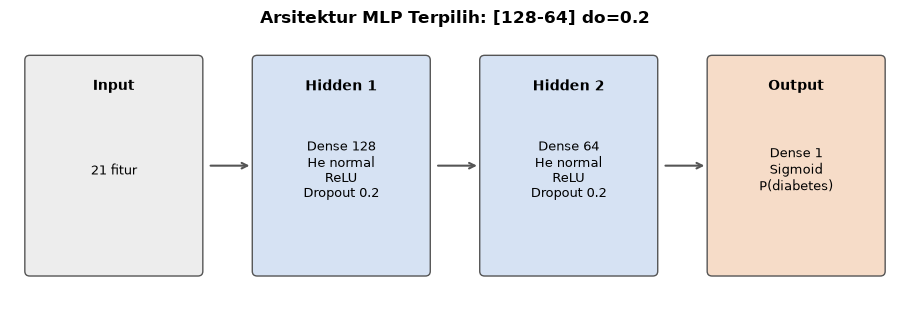

Model: "mlp_diabetes"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ fitur_input (InputLayer)        │ (None, 21)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │         2,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_1 (Activation)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_2 (Activation)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,137 (43.50 KB)

 Trainable params: 11,137 (43.50 KB)

 Non-trainable params: 0 (0.00 B)

In [22]:
def gambar_arsitektur(cfg, nama_file):
    layers = [("Input", f"{len(config.FEATURE_COLS)} fitur", "#EDEDED")]
    for i, u in enumerate(cfg["hidden_units"], start=1):
        detail = [f"Dense {u}", "He normal"]
        if cfg.get("l2", 0) > 0:
            detail.append(f"L2 {cfg['l2']:g}")
        if cfg.get("batch_norm"):
            detail.append("Batch Normalization")
        detail.append("ReLU")
        if cfg["dropout"] > 0:
            detail.append(f"Dropout {cfg['dropout']}")
        layers.append((f"Hidden {i}", "\n".join(detail), "#D6E2F3"))
    layers.append(("Output", "Dense 1\nSigmoid\nP(diabetes)", "#F6DCC8"))

    fig, ax = plt.subplots(figsize=(2.3 * len(layers), 3.2))
    for i, (judul, isi, warna) in enumerate(layers):
        x = i * 2.3
        ax.add_patch(mpatches.FancyBboxPatch((x, 0), 1.7, 2.2, boxstyle="round,pad=0.05",
                                             fc=warna, ec="#555555", lw=1))
        ax.text(x + 0.85, 2.0, judul, ha="center", va="top", fontweight="bold", fontsize=10)
        ax.text(x + 0.85, 1.05, isi, ha="center", va="center", fontsize=9)
        if i < len(layers) - 1:
            ax.annotate("", xy=(x + 2.25, 1.1), xytext=(x + 1.8, 1.1),
                        arrowprops=dict(arrowstyle="->", color="#555555", lw=1.5))
    ax.set_xlim(-0.2, 2.3 * len(layers) - 0.4)
    ax.set_ylim(-0.3, 2.5)
    ax.axis("off")
    ax.set_title(f"Arsitektur MLP Terpilih: {M.config_label(cfg)}", fontweight="bold")
    fig.tight_layout()
    save_fig(fig, nama_file)
    plt.show()

gambar_arsitektur(cfg_final, "model_04_diagram_arsitektur")
model_final = M.build_model(**cfg_final)
model_final.summary()

**Interpretasi:** Arsitektur terpilih terdiri dari input 21 fitur, dua hidden layer berisi 128 dan 64 neuron dengan aktivasi ReLU dan dropout 0,2, lalu satu neuron sigmoid sebagai output probabilitas diabetes. Total parameternya 11.137 dengan ukuran bobot sekitar 43,5 KB. Model sekecil ini cepat dipakai untuk prediksi dan ringan untuk di-deploy ke aplikasi.

## **11. Kurva Training: Train vs Validation**

Kurva di bawah berasal dari training konfigurasi terpilih dengan 3 seed. Garis putus-putus menunjukkan data train dan garis utuh menunjukkan data validation. Garis vertikal tipis menandai epoch dengan PR-AUC validation terbaik, yaitu bobot yang disimpan oleh ModelCheckpoint dan dikembalikan oleh EarlyStopping.

Ada satu hal penting saat membaca kurva ini. Loss dan PR-AUC train di sini dihitung **selama training**, ketika dropout masih aktif dan bobot masih berubah di tengah epoch. Karena itu nilai train bisa terlihat lebih buruk daripada validation. Untuk mengukur gap overfitting yang adil, tabel di bawah grafik memakai PR-AUC train yang dihitung ulang setelah training selesai, saat dropout sudah nonaktif.

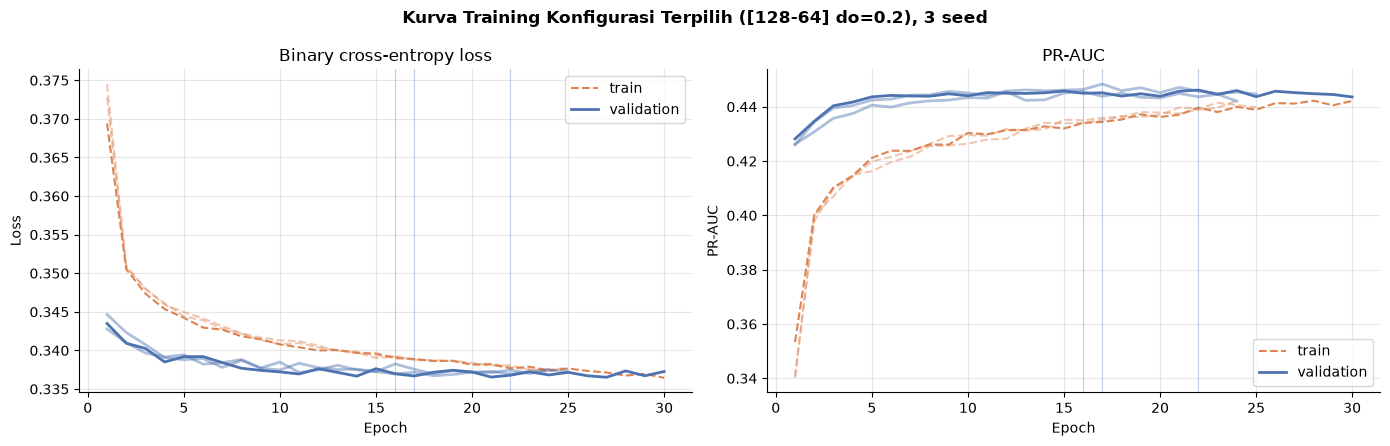

,seed,epoch dijalankan,epoch terbaik,train loss,val loss,train PR-AUC (tanpa dropout),val PR-AUC,gap,val ROC-AUC,detik/epoch
0,42,30,22,0.3377,0.3368,0.4517,0.4463,0.0054,0.8190,2.50
1,123,24,16,0.3393,0.3383,0.4482,0.4456,0.0026,0.8181,2.54
2,2026,25,17,0.3388,0.3372,0.4496,0.4485,0.0011,0.8189,2.46


In [23]:
nama_final = pilih_e2b
hist_final = {seed: hist_e2b[f"{nama_final}|{seed}"] for seed in M.SEEDS}

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for metrik, ax, judul in [("loss", axes[0], "Binary cross-entropy loss"), ("pr_auc", axes[1], "PR-AUC")]:
    for j, seed in enumerate(M.SEEDS):
        h = hist_final[seed]
        ep = np.arange(1, len(h[metrik]) + 1)
        alpha = 1.0 if j == 0 else 0.45
        ax.plot(ep, h[metrik], ls="--", lw=1.5, color=WARNA_TRAIN, alpha=alpha,
                label="train" if j == 0 else None)
        ax.plot(ep, h[f"val_{metrik}"], ls="-", lw=2, color=WARNA_VAL, alpha=alpha,
                label="validation" if j == 0 else None)
        best = int(np.argmax(h["val_pr_auc"])) + 1
        ax.axvline(best, color=WARNA_VAL, lw=0.8, alpha=0.35)
    ax.set_xlabel("Epoch")
    ax.set_title(judul)
    ax.legend()
axes[0].set_ylabel("Loss")
axes[1].set_ylabel("PR-AUC")
fig.suptitle(f"Kurva Training Konfigurasi Terpilih ({M.config_label(cfg_final)}), 3 seed", fontweight="bold")
fig.tight_layout()
save_fig(fig, "model_05_kurva_training")
plt.show()

kurva = runs_e2b[runs_e2b["skenario"] == nama_final][
    ["seed", "epochs_run", "best_epoch", "train_loss_best", "val_loss_best",
     "train_pr_auc", "val_pr_auc", "gap_pr_auc", "val_roc_auc", "seconds_per_epoch"]]
kurva.columns = ["seed", "epoch dijalankan", "epoch terbaik", "train loss", "val loss",
                 "train PR-AUC (tanpa dropout)", "val PR-AUC", "gap", "val ROC-AUC", "detik/epoch"]
kurva.round(4)

**Interpretasi:** Ketiga seed menunjukkan pola yang hampir sama. Epoch terbaiknya ada di epoch 22, 16, dan 17. Training berhenti di epoch 30, 24, dan 25, tepat 8 epoch setelah epoch terbaik sesuai nilai patience EarlyStopping.

Dari grafik loss, val loss turun tajam di 4 sampai 5 epoch pertama lalu mendatar di kisaran 0,337. Train loss mulai dari angka yang lebih tinggi dan terus turun perlahan sampai hampir sama dengan val loss di akhir training. Train loss lebih tinggi karena dihitung saat dropout aktif. Pola yang sama terlihat di grafik PR-AUC, di mana garis train selalu di bawah validation. Hal ini bukan tanda masalah, melainkan efek dropout.

Untuk menilai overfitting secara adil, dipakai PR-AUC train yang dihitung ulang tanpa dropout. Hasilnya 0,4482 sampai 0,4517, sedangkan PR-AUC validation 0,4456 sampai 0,4485. Gap-nya hanya 0,0011 sampai 0,0054, jadi **tidak ada tanda overfitting**. Val loss juga tidak berbalik naik secara tajam setelah epoch terbaik.

Untuk kemungkinan *underfitting*, performa train dan validation memang sama-sama berhenti di sekitar 0,45, tetapi eksperimen E1 menunjukkan bahwa model hingga empat kali lebih besar pun tidak menaikkan PR-AUC train secara berarti. Jadi batas ini lebih mungkin berasal dari keterbatasan data, yaitu data survei yang dilaporkan sendiri, 1,37% profil fitur yang ambigu, dan responden prediabetes yang tercampur di label 0. Sebagai pembanding, PR-AUC validation 0,447 sekitar 2,9 kali lipat dari nilai acak (0,153), dan ROC-AUC validation sekitar 0,819.

## **12. Ringkasan Seluruh Skenario**

Tabel ini menggabungkan seluruh skenario dari E1 sampai E2b dan disimpan ke `reports/results/03_ringkasan_skenario.csv` sebagai bahan tabel perbandingan skenario di laporan.

In [24]:
ringkasan_semua = pd.concat([
    tabel_ringkas(ringkas_e1, pilih_e1).assign(tahap="E1"),
    tabel_ringkas(ringkas_e2a, pilih_e2a).assign(tahap="E2a"),
    tabel_ringkas(ringkas_e2b, pilih_e2b).assign(tahap="E2b"),
]).rename_axis("skenario").reset_index()
ringkasan_semua = ringkasan_semua[["tahap", "skenario"] + [c for c in ringkasan_semua.columns
                                                         if c not in ("tahap", "skenario")]]
ringkasan_semua.to_csv(config.RESULTS_DIR / "03_ringkasan_skenario.csv", index=False)
ringkasan_semua

,tahap,skenario,konfigurasi,parameter,val PR-AUC,std,val ROC-AUC,train PR-AUC,gap train-val,epoch terbaik,detik/run,setara terbaik,dipilih
0,E1,64-32,[64-32] do=0.2,3521,0.4436,0.0011,0.8186,0.4431,-0.0005,23.0,67.0,False,
1,E1,128-64,[128-64] do=0.2,11137,0.4468,0.0015,0.8187,0.4498,0.0030,18.3,66.0,True,ya
2,E1,256-128,[256-128] do=0.2,38657,0.4469,0.0008,0.8190,0.4515,0.0046,12.7,71.0,True,
3,E1,128-64-32,[128-64-32] do=0.2,13185,0.4459,0.0006,0.8184,0.4445,-0.0014,17.3,66.0,False,
4,E1,256-128-64,[256-128-64] do=0.2,46849,0.4462,0.0021,0.8185,0.4476,0.0013,12.7,73.0,True,
5,E2a,dropout 0.0,[128-64] do=0.0,11137,0.4449,0.0008,0.8174,0.4458,0.0009,6.7,26.0,False,
6,E2a,dropout 0.2,[128-64] do=0.2,11137,0.4468,0.0015,0.8187,0.4498,0.0030,18.3,66.0,True,ya
7,E2a,dropout 0.3,[128-64] do=0.3,11137,0.4462,0.0013,0.8185,0.4438,-0.0024,16.0,59.0,True,
8,E2b,tanpa tambahan,[128-64] do=0.2,11137,0.4468,0.0015,0.8187,0.4498,0.0030,18.3,66.0,True,ya
9,E2b,L2 1e-5,[128-64] do=0.2 l2=1e-05,11137,0.4473,0.0005,0.8189,0.4475,0.0002,18.3,59.0,True,


## **13. Kesimpulan dan Langkah Berikutnya**

Konfigurasi MLP hasil notebook ini:

| Komponen | Nilai |
|---|---|
| Hidden layer | 2 layer, 128 dan 64 neuron |
| Aktivasi dan inisialisasi | ReLU, He normal |
| Dropout | 0,2 |
| L2 dan Batch Normalization | Tidak dipakai |
| Output | 1 neuron sigmoid |
| Optimizer | Adam, learning rate 0,001 (sementara) |
| Batch size | 512 (sementara) |
| Callback | EarlyStopping (patience 8) dan ModelCheckpoint, keduanya memantau PR-AUC validation |
| Jumlah parameter | 11.137 |
| PR-AUC validation | 0,4468 +- 0,0015 (3 seed) |
| ROC-AUC validation | 0,8187 |

Temuan utamanya:
1. Dari 12 skenario yang diuji, PR-AUC validation hanya bergerak di rentang 0,4436 sampai 0,4478. Pilihan arsitektur dan regularisasi berpengaruh sangat kecil dibanding batasan dari data itu sendiri.
2. Dropout 0,2 terbukti membantu dibanding tanpa dropout (0,4468 berbanding 0,4449) dan menunda overfitting.
3. Model yang lebih besar tidak lebih baik, jadi model kecil dipilih karena lebih efisien.
4. Tidak ditemukan tanda overfitting yang berarti pada konfigurasi terpilih.

Semua angka di notebook ini adalah hasil di data **validation** dan dipakai untuk memilih konfigurasi. Angka ini bukan performa akhir model dan tidak boleh ditulis sebagai hasil evaluasi di laporan. Performa akhir hanya diukur sekali di data test pada notebook 07.

**Langkah berikutnya:** notebook `04_eksperimen_optimasi.ipynb` membaca konfigurasi dari `reports/results/03_konfigurasi_terpilih.json`, lalu menguji kombinasi learning rate dan batch size sebelum melatih model final.